Accuracy: 0.7989
F1-Score: 0.8246

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.80      0.76        75
           1       0.85      0.80      0.82       109

    accuracy                           0.80       184
   macro avg       0.79      0.80      0.79       184
weighted avg       0.80      0.80      0.80       184



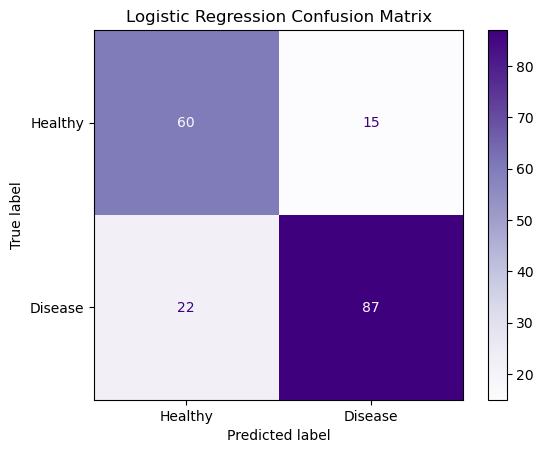

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, f1_score, ConfusionMatrixDisplay

# 1. Load and Prepare Data
df = pd.read_csv('heart_disease_uci.csv')
df = df.drop(columns=['id', 'dataset'])
df['target'] = (df['num'] > 0).astype(int)
df = df.drop(columns=['num'])

X = df.drop(columns=['target'])
y = df['target']

# 2. Preprocessing
numeric_features = X.select_dtypes(include=['number']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'bool']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_features),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(handle_unknown='ignore'))]), categorical_features)
    ])

# 3. Model Pipeline
# max_iter is increased to ensure the solver converges
lr_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

# 4. Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Fit & Predict
lr_model.fit(X_train, y_train)
y_pred = lr_model.predict(X_test)

# 6. Evaluation
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 7. Confusion Matrix
ConfusionMatrixDisplay.from_estimator(
    lr_model, X_test, y_test,
    display_labels=['Healthy', 'Disease'],
    cmap=plt.cm.Purples
)
plt.title('Logistic Regression Confusion Matrix')
plt.show()